# Walmart Sales

Objectif : Concevoir un modèle de Machine Learning capable d'estimer les ventes hebdomadaires des magasins Walmart. 
<br> L'enjeu est de quantifier l'impact des indicateurs économiques (Chômage, IPC, ...) pour optimiser les futures campagnes marketing.   

Plan d'action :
1. EDA & Prétraitement : Nettoyage, gestion des valeurs aberrantes et manquantes, décomposition des dates. 
2. Baseline : Modèle de régression linéaire et interprétation des coefficients. 
3. Optimisation : Régularisation (Ridge/Lasso) pour éviter le surapprentissage et réglage des hyperparamètres via GridSearchCV.


---
# Partie 1 - EDA et prétraitement des données

## 1.1 Imports et chargement des données

In [1]:
# ── Manipulation de données ────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualisation ──────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# ── Prétraitement scikit-learn ─────────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ── Modèles ───────────────────────────────────────────────────────────
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# ── Évaluation et sélection ───────────────────────────────────────────
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [18]:
# ── Chargement ────────────────────────────────────────────────────────
file_path = "data/Walmart_Store_sales.csv"
df = pd.read_csv(file_path)
print("Shape du dataset :", df.shape)
df.head()

Shape du dataset : (150, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,6.0,18-02-2011,1572117.54,NaN,59.61,3.045,214.777523,6.858
1,13.0,25-03-2011,1807545.43,0.0,42.38,3.435,128.616064,7.470
2,17.0,27-07-2012,NaN,0.0,NaN,NaN,130.719581,5.936
3,11.0,NaN,1244390.03,0.0,84.57,NaN,214.556497,7.346
4,6.0,28-05-2010,1644470.66,0.0,78.89,2.759,212.412888,7.092


## 1.2 Analyse exploratoire des données (EDA)

In [3]:
df.describe(include='all')

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,150.000000,132,1.360000e+02,138.000000,132.000000,136.000000,138.000000,135.000000
unique,NaN,85,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,19-10-2012,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN
mean,9.866667,NaN,1.249536e+06,0.079710,61.398106,3.320853,179.898509,7.598430
std,6.231191,NaN,6.474630e+05,0.271831,18.378901,0.478149,40.274956,1.577173
min,1.000000,NaN,2.689290e+05,0.000000,18.790000,2.514000,126.111903,5.143000
25%,4.000000,NaN,6.050757e+05,0.000000,45.587500,2.852250,131.970831,6.597500
50%,9.000000,NaN,1.261424e+06,0.000000,62.985000,3.451000,197.908893,7.470000
75%,15.750000,NaN,1.806386e+06,0.000000,76.345000,3.706250,214.934616,8.150000


### Valeurs manquantes

In [4]:
print("Pourcentage des valeurs manquantes par colonne :")
display(df.isnull().mean() * 100)

print("Nombre des valeurs manquantes par colonne :")
display(df.isnull().sum())

Pourcentage des valeurs manquantes par colonne :


Store            0.000000
Date            12.000000
Weekly_Sales     9.333333
Holiday_Flag     8.000000
Temperature     12.000000
Fuel_Price       9.333333
CPI              8.000000
Unemployment    10.000000
dtype: float64

Nombre des valeurs manquantes par colonne :


Store            0
Date            18
Weekly_Sales    14
Holiday_Flag    12
Temperature     18
Fuel_Price      14
CPI             12
Unemployment    15
dtype: int64

**Observation :** La colonne `Weekly_Sales` (variable cible) contient 14 valeurs manquantes (9.3%).  
Avec moins de 10% de NaN sur une cible, la suppression est le choix approprié - l'imputation de la variable cible introduirait un biais dans les prédictions.

### Graphique 1 - Distribution de la variable cible `Weekly_Sales`

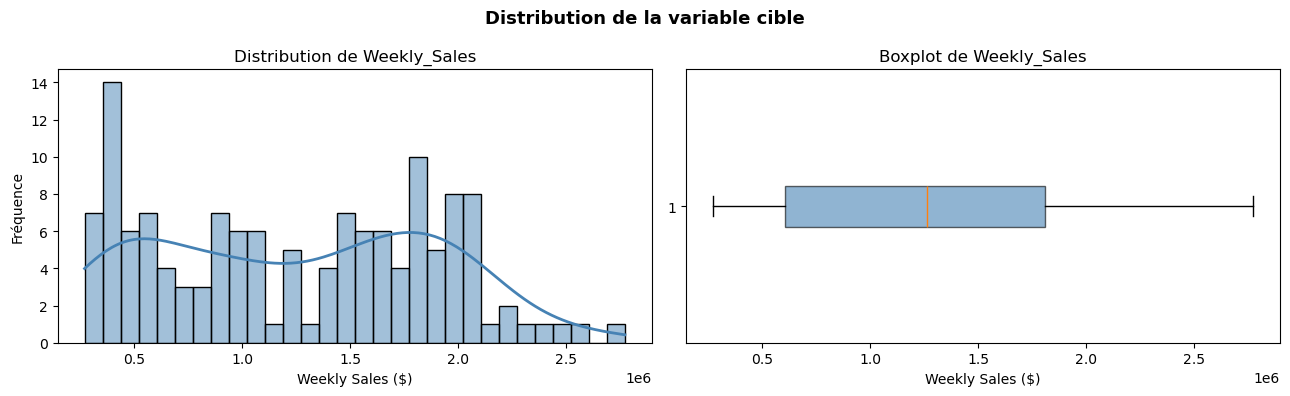

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

data = df['Weekly_Sales'].dropna()

sns.histplot(data, bins=30, kde=True, color='steelblue',
             kde_kws={'bw_adjust': 1},
             line_kws={'color': 'red', 'linewidth': 2},
             ax=axes[0])
axes[0].set_title('Distribution de Weekly_Sales')
axes[0].set_xlabel('Weekly Sales ($)')
axes[0].set_ylabel('Fréquence')

axes[1].boxplot(data, vert=False, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title('Boxplot de Weekly_Sales')
axes[1].set_xlabel('Weekly Sales ($)')

plt.suptitle('Distribution de la variable cible', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Observation :** La distribution des ventes hebdomadaires s'étend de ~270 k$ à ~2,8 M$ avec un profil bimodal (deux concentrations visibles, l'une vers 400 k$ et l'autre vers 1,6 M$), suggérant l'existence de deux groupes de magasins aux niveaux de performance très différents.  
La médiane se situe autour de 1,2 M$ (boxplot). La moustache droite allongée indique la présence de ventes hebdomadaires élevées qui reflètent l'hétérogénéité réelle entre magasins, sans pour autant être des erreurs de saisie.

### Graphique 2 - Évolution des ventes dans le temps

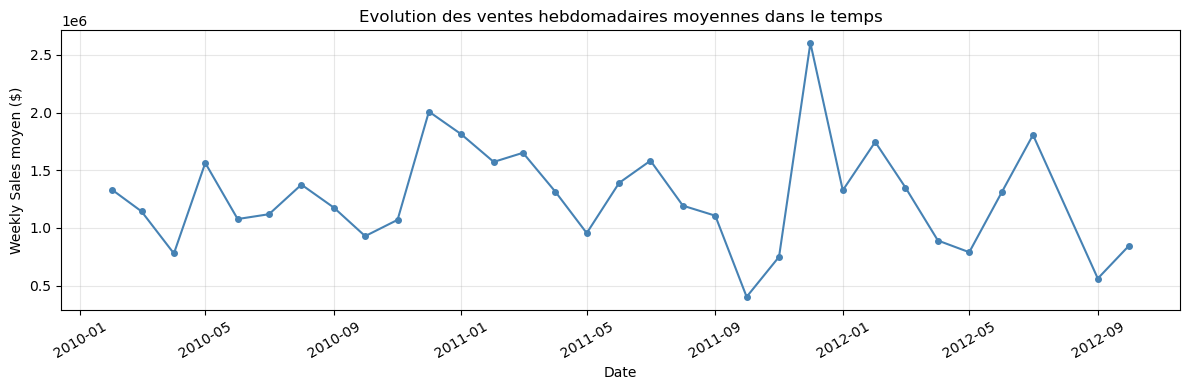

In [6]:
df_tmp = df.copy()
df_tmp['Date'] = pd.to_datetime(df_tmp['Date'], dayfirst=True)
monthly = df_tmp.groupby(df_tmp['Date'].dt.to_period('M'))['Weekly_Sales'].mean().reset_index()
monthly['Date'] = monthly['Date'].dt.to_timestamp()

plt.figure(figsize=(12, 4))
plt.plot(monthly['Date'], monthly['Weekly_Sales'],
         marker='o', color='steelblue', linewidth=1.5, markersize=4)
plt.title('Evolution des ventes hebdomadaires moyennes dans le temps', fontsize=12)
plt.xlabel('Date')
plt.ylabel('Weekly Sales moyen ($)')
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation :** Les ventes hebdomaiares moyennes présentent des fluctuations, avec des pics réguliers.  
Possibilté de pésence de tendance saisonnière --> nécessité d'extraction des features temporelles (`Year`, `Month`, `Day`) depuis la colonne `Date`.


### Graphique 3 - Ventes par magasin (hétérogénéité inter-magasins)

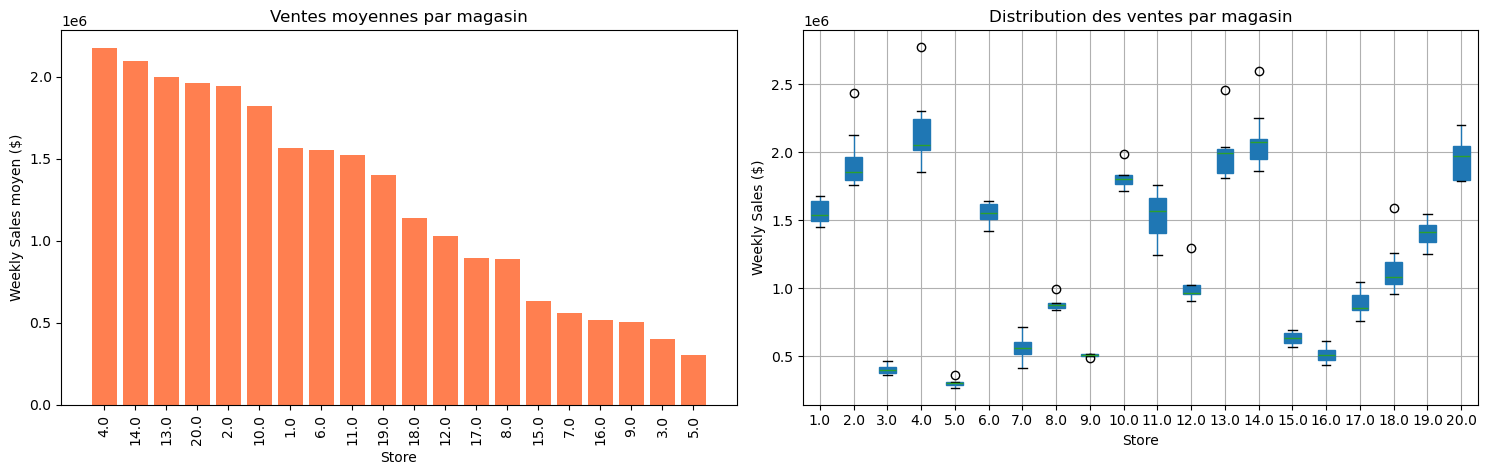

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

store_avg = df.groupby('Store')['Weekly_Sales'].mean().sort_values(ascending=False)
axes[0].bar(store_avg.index.astype(str), store_avg.values, color='coral')
axes[0].set_title('Ventes moyennes par magasin')
axes[0].set_xlabel('Store')
axes[0].set_ylabel('Weekly Sales moyen ($)')
axes[0].tick_params(axis='x', rotation=90)

df.boxplot(column='Weekly_Sales', by='Store', ax=axes[1], patch_artist=True)
axes[1].set_title('Distribution des ventes par magasin')
axes[1].set_xlabel('Store')
axes[1].set_ylabel('Weekly Sales ($)')
plt.suptitle('')
plt.tight_layout()
plt.show()

**Observation :** L'hétérogénéité inter-magasins est considérable - certains génèrent jusqu'à 4 fois plus de ventes que d'autres.  
La colonne `Store` sera logiquement une variable explicative puissante du modèle.


### Graphique 4 - Indicateurs économiques et jours fériés vs ventes

Ce graphique examine l'influence directe de chaque indicateur économique sur les ventes hebdomadaires.

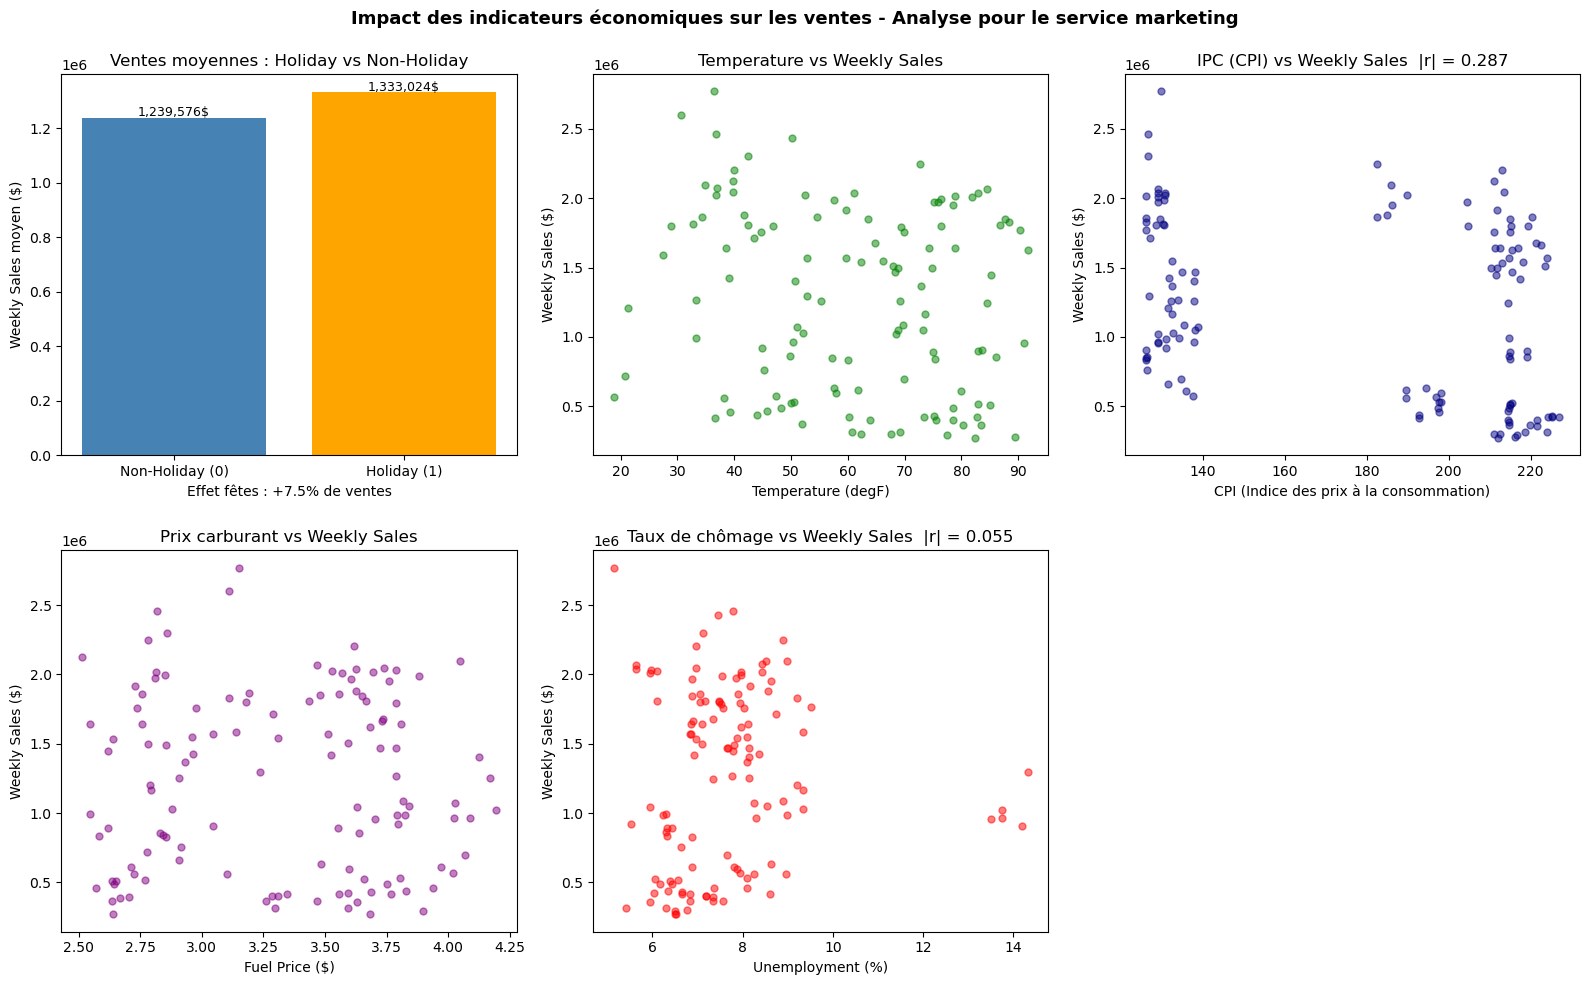

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# ── Holiday Flag ──────────────────────────────────────────────────────
hol = df.groupby('Holiday_Flag')['Weekly_Sales'].mean()
axes[0, 0].bar(['Non-Holiday (0)', 'Holiday (1)'], hol.values, color=['steelblue', 'orange'])
axes[0, 0].set_title('Ventes moyennes : Holiday vs Non-Holiday')
axes[0, 0].set_ylabel('Weekly Sales moyen ($)')
for i, v in enumerate(hol.values):
    axes[0, 0].text(i, v + 5000, f'{v:,.0f}$', ha='center', fontsize=9)
diff_hol = (hol[1] - hol[0]) / hol[0] * 100
axes[0, 0].set_xlabel(f'Effet fêtes : +{diff_hol:.1f}% de ventes')

# ── Température ───────────────────────────────────────────────────────
axes[0, 1].scatter(df['Temperature'], df['Weekly_Sales'], alpha=0.5, color='green', s=25)
axes[0, 1].set_title('Temperature vs Weekly Sales')
axes[0, 1].set_xlabel('Temperature (degF)')
axes[0, 1].set_ylabel('Weekly Sales ($)')

# ── CPI ───────────────────────────────────────────────────────────────
axes[0, 2].scatter(df['CPI'], df['Weekly_Sales'], alpha=0.5, color='navy', s=25)
cpi_valid = df[['CPI', 'Weekly_Sales']].dropna()
corr_cpi = cpi_valid['CPI'].corr(cpi_valid['Weekly_Sales'])
axes[0, 2].set_title(f'IPC (CPI) vs Weekly Sales  |r| = {abs(corr_cpi):.3f}')
axes[0, 2].set_xlabel('CPI (Indice des prix à la consommation)')
axes[0, 2].set_ylabel('Weekly Sales ($)')

# ── Prix carburant ────────────────────────────────────────────────────
axes[1, 0].scatter(df['Fuel_Price'], df['Weekly_Sales'], alpha=0.5, color='purple', s=25)
axes[1, 0].set_title('Prix carburant vs Weekly Sales')
axes[1, 0].set_xlabel('Fuel Price ($)')
axes[1, 0].set_ylabel('Weekly Sales ($)')

# ── Chômage ───────────────────────────────────────────────────────────
axes[1, 1].scatter(df['Unemployment'], df['Weekly_Sales'], alpha=0.5, color='red', s=25)
unemp_valid = df[['Unemployment', 'Weekly_Sales']].dropna()
corr_u = unemp_valid['Unemployment'].corr(unemp_valid['Weekly_Sales'])
axes[1, 1].set_title(f'Taux de chômage vs Weekly Sales  |r| = {abs(corr_u):.3f}')
axes[1, 1].set_xlabel('Unemployment (%)')
axes[1, 1].set_ylabel('Weekly Sales ($)')

# ── Case vide (1, 2) ──────────────────────────────────────────────────
axes[1, 2].axis('off')

plt.suptitle('Impact des indicateurs économiques sur les ventes - Analyse pour le service marketing',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Observations :**
- **Jours fériés** : les semaines avec jours fériés génèrent en moyenne **+7,5% de ventes** supplémentaires. 
C'est le levier marketing le plus directement actionnable : concentrer les budgets promotionnels sur ces périodes.
- **IPC (Indice des Prix à la Consommation)** : la corrélation est négative (r ≈ -0,29, la plus élevée parmi les indicateurs économiques). 
Une hausse de l'IPC reflète une perte de pouvoir d'achat, ce qui se traduit par une réduction des achats. 
Le service marketing devra adapter son positionnement prix (offres, promotions) lors des phases d'inflation soutenue.
- **Taux de chômage** : la corrélation brute avec les ventes est très faible (|r| = 0,055) et même légèrement positive ; aucune tendance nette n'apparaît sur le nuage de points. 
<br>Cet indicateur reste utile pour orienter les campagnes géographiques : les magasins situés dans des bassins d'emploi fragilisés peuvent justifier une stratégie promotionnelle renforcée.
- **Prix du carburant** : relation très bruitée, sans tendance linéaire claire.
- **Température** : aucune corrélation exploitable directement sur les ventes globales.

- **Conclusion** : aucun indicateur pris isolément n'explique suffisamment les ventes. 
C'est leur **combinaison dans le modèle** qui permettra de capter et quantifier leur influence respective.

### Graphique 5 - Matrice de corrélation

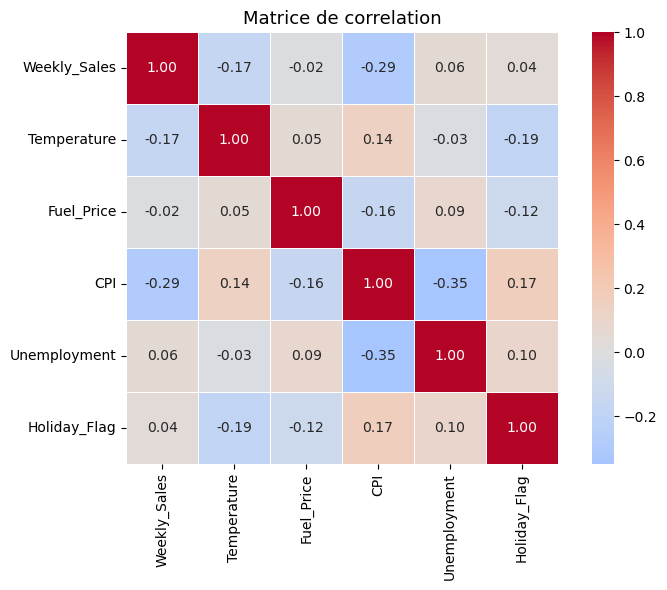

In [9]:
corr_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix,
            annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, annot_kws={'size': 10})
plt.title('Matrice de correlation', fontsize=13)
plt.tight_layout()
plt.show()

**Observations :**
- Aucune variable numérique,  prise isolément, n'est fortement corrélée à `Weekly_Sales`.
- `CPI` et `Unemployment` sont un petit peu corrélés entre eux --> multicolinéarité potentielle à surveiller.

### Graphique 6 - Corrélation de chaque feature avec `Weekly_Sales`

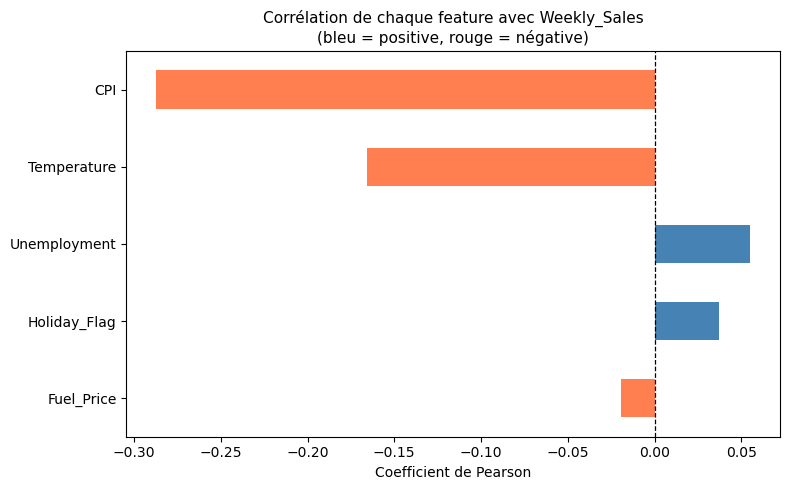

Classement par corrélation absolue avec Weekly_Sales :
CPI             0.287227
Temperature     0.165991
Unemployment    0.055191
Holiday_Flag    0.037037
Fuel_Price      0.019087


In [10]:
cols_numeriques = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag']

corr_target = (df[cols_numeriques + ['Weekly_Sales']]
               .corr()['Weekly_Sales']
               .drop('Weekly_Sales')
               .sort_values(key=abs, ascending=True))

colors = ['coral' if v < 0 else 'steelblue' for v in corr_target]

plt.figure(figsize=(8, 5))
corr_target.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.9, linestyle='--')
plt.title("Corrélation de chaque feature avec Weekly_Sales\n"
          "(bleu = positive, rouge = négative)", fontsize=11)
plt.xlabel("Coefficient de Pearson")
plt.tight_layout()
plt.show()

print("Classement par corrélation absolue avec Weekly_Sales :")
print(corr_target.abs().sort_values(ascending=False).to_string())

**Observation :** Aucune variable numérique ne dépasse |r| = 0,30 avec la cible.
<br>`CPI` (|r| = 0,287) est l'indicateur économique le mieux corrélé : une hausse de l'IPC est associée à une baisse des ventes, 
ce qui reflète la pression sur le pouvoir d'achat des consommateurs.  
Ces corrélations individuelles restent faibles mais les indicateurs agissent **conjointement** - c'est précisément ce que le modèle de régression va capturer en les combinant.  
La faible corrélation linéaire individuelle ne signifie pas une faible importance prédictive : le modèle exploitera leurs interactions et leurs effets combinés.


## 1.3 Prétraitement des données avec pandas

### Étape 1 - Suppression des lignes où la variable cible est manquante

On n'impute pas la variable cible : cela introduirait un biais dans les prédictions.


In [19]:
print(f"Shape avant : {df.shape}")
df = df.dropna(subset=['Weekly_Sales'])
print(f"Shape après suppression des NaN de Weekly_Sales : {df.shape}")

Shape avant : (150, 8)
Shape après suppression des NaN de Weekly_Sales : (136, 8)


### Étape 2 - Création de features numériques depuis la colonne `Date`


In [20]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

df['Year']      = df['Date'].dt.year
df['Month']     = df['Date'].dt.month
df['Day']       = df['Date'].dt.day
df['DayOfWeek'] = df['Date'].dt.dayofweek   # 0=lundi, 6=dimanche

df.drop(columns=['Date'], inplace=True)

print("Features temporelles créées : Year, Month, Day, DayOfWeek")
df.head()

Features temporelles créées : Year, Month, Day, DayOfWeek


,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Day,DayOfWeek
0,6.0,1572117.54,NaN,59.61,3.045,214.777523,6.858,2011.0,2.0,18.0,4.0
1,13.0,1807545.43,0.0,42.38,3.435,128.616064,7.470,2011.0,3.0,25.0,4.0
3,11.0,1244390.03,0.0,84.57,NaN,214.556497,7.346,NaN,NaN,NaN,NaN
4,6.0,1644470.66,0.0,78.89,2.759,212.412888,7.092,2010.0,5.0,28.0,4.0
5,4.0,1857533.70,0.0,NaN,2.756,126.160226,7.896,2010.0,5.0,28.0,4.0


### Vérification de la variation des features temporelles


In [21]:
print("Valeurs uniques par feature temporelle, hors NaN :")
print(df[['Year', 'Month', 'Day', 'DayOfWeek']].nunique())

Valeurs uniques par feature temporelle, hors NaN :
Year          3
Month        12
Day          30
DayOfWeek     1
dtype: int64


**Observation :** Les données Walmart sont des relevés **hebdomadaires du vendredi** (DayOfWeek = 4).  
`DayOfWeek` ne contient qu'une seule valeur -> aucune information apportée au modèle. Elle est supprimée ci-dessous.


In [22]:
df.drop(columns=['DayOfWeek'], inplace=True)
print("Colonne DayOfWeek supprimée - colonnes restantes :", df.columns.tolist())

Colonne DayOfWeek supprimée - colonnes restantes : ['Store', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'Day']


### Étape 3 - Analyse des outliers : [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR]

In [23]:
outlier_cols = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    irq = q3 - q1
    lower, upper = q1 - 1.5 * irq, q3 + 1.5 * irq
    number = df[((df[col] >= lower) & (df[col] <= upper)) | df[col].isna()][col].count()
    print(f"{col} ->  {df[col].notna().sum() - number} outlier")

    if 0 != (df[col].notna().sum() - number):
        print(f"Les outliers de {col} sont:\n {df[(df[col] < lower) | (df[col] > upper)][col].values}")


Temperature ->  0 outlier
Fuel_Price ->  0 outlier
CPI ->  0 outlier
Unemployment ->  5 outlier
Les outliers de Unemployment sont:
 [13.736 14.313 13.503 13.736 14.18 ]


Même s'il y a 5 outliers dans Unemployment, on voit bien que leurs valeurs ne sont pas vraiment aberrantes ou trop grandes. Les valeurs restent tout à fait plausibles. Par conséquent, il vaut mieux les garder.

In [24]:
# Drop the null values in Date (Year, Month, Day) and Holiday_Flag
df = df.dropna(subset=["Year", "Holiday_Flag"])
df.shape

(109, 10)

## 1.4 Prétraitement avec scikit-learn

- **Variables catégorielles** : `Store`, `Month`, `Holiday_Flag` - OneHotEncoder
- **Variables numériques** : `Temperature`, `Fuel_Price`, `CPI`, `Unemployment`, `Year` - SimpleImputer + StandardScaler


In [25]:
cat_cols = ['Store', 'Month', 'Holiday_Flag']
num_cols = ['CPI', 'Unemployment', 'Fuel_Price', 'Year', 'Temperature']

X = df[cat_cols + num_cols].copy()
X['Store'] = X['Store'].astype(str)
y = df['Weekly_Sales']

print(f"Shape X : {X.shape}")
print(f"Shape y : {y.shape}")

Shape X : (109, 8)
Shape y : (109,)


### Découpage Train / Test (80% / 20%)

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13)

print(f"Train : {X_train.shape[0]} observations")
print(f"Test  : {X_test.shape[0]} observations")

Train : 87 observations
Test  : 22 observations


### Pipeline de prétraitement

In [27]:
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Remplace les NaN 
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('ohe', OneHotEncoder(
        drop='first',
        sparse_output=False,
        handle_unknown='ignore'
    ))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

X_train_prepared = preprocessor.fit_transform(X_train)
print(f"Shape de X_train après pretraitement : {X_train_prepared.shape}")
print(f"Nombre de Features : {X_train_prepared.shape[1]}")

Shape de X_train après pretraitement : (87, 36)
Nombre de Features : 36


---
# Partie 2 - Modèle de base - Régression linéaire

## 2.1 Entraînement du modèle

In [28]:
lr_pipe = Pipeline([
    ('prep',  preprocessor),
    ('model', LinearRegression())
])

lr_pipe.fit(X_train, y_train)
print("Modèle entraîné")

Modèle entraîné


## 2.2 Évaluation des performances

On évalue sur le train et le test pour détecter un éventuel overfitting.  
Un écart important entre R² train et R² test signale que le modèle mémorise les données au lieu de généraliser.


In [29]:
y_pred_train = lr_pipe.predict(X_train)
y_pred_test  = lr_pipe.predict(X_test)

r2_train   = r2_score(y_train, y_pred_train)
mae_train  = mean_absolute_error(y_train, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))

r2_test    = r2_score(y_test,  y_pred_test)
mae_test   = mean_absolute_error(y_test,  y_pred_test)
rmse_test  = np.sqrt(mean_squared_error(y_test,  y_pred_test))

print("=" * 58)
print("       Regression Lineaire - Performances")
print("=" * 58)
print(f"{'Metrique':<12} {'Train':>14} {'Test':>14}   Ecart")
print("-" * 58)
print(f"{'R2':<12} {r2_train:>14.4f} {r2_test:>14.4f}   {r2_train - r2_test:.4f}")
print(f"{'MAE ($)':<12} {mae_train:>14,.0f} {mae_test:>14,.0f}   {mae_test - mae_train:+,.0f}")
print(f"{'RMSE ($)':<12} {rmse_train:>14,.0f} {rmse_test:>14,.0f}   {rmse_test - rmse_train:+,.0f}")
print("=" * 58)

       Regression Lineaire - Performances
Metrique              Train           Test   Ecart
----------------------------------------------------------
R2                   0.9841         0.9742   0.0099
MAE ($)              65,920         87,636   +21,716
RMSE ($)             83,773        106,779   +23,006


**Analyse :** Le R² de test (0.97) est satisfaisant, et l'écart avec le R² d'entraînement (0.98) est trés réduit --> pas d'overfitting.
Même s'il n'y a pas d'overfitting apparent, ça ne nous empêche pas d'essayer de réduire les erreurs MAE et RMSE avec la régularisation.


### Graphique 7 - Diagnostic du modèle : Predicted vs Actual et résidus


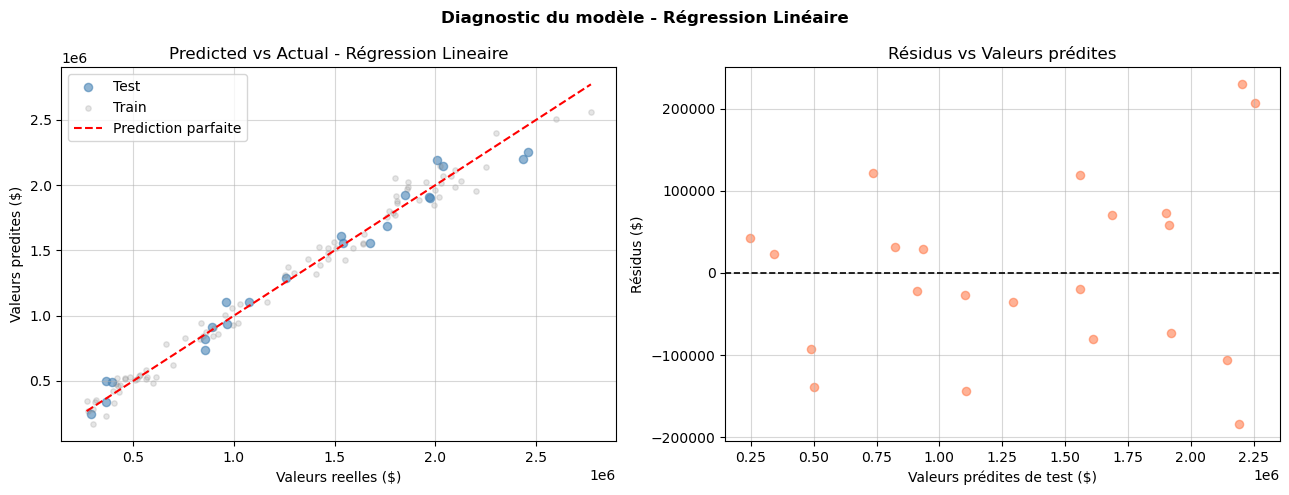

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Predicted vs Actual ───────────────────────────────────────────────
axes[0].scatter(y_test,  y_pred_test,  alpha=0.6, color='steelblue', s=35, label='Test')
axes[0].scatter(y_train, y_pred_train, alpha=0.2, color='gray',      s=15, label='Train')
min_val = min(float(y_train.min()), float(y_test.min()))
max_val = max(float(y_train.max()), float(y_test.max()))
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Prediction parfaite')
axes[0].set_title('Predicted vs Actual - Régression Lineaire')
axes[0].set_xlabel('Valeurs reelles ($)')
axes[0].set_ylabel('Valeurs predites ($)')
axes[0].grid(alpha=0.5)
axes[0].legend()

# ── Residus ───────────────────────────────────────────────────────────
residuals = y_test - y_pred_test
axes[1].scatter(y_pred_test, residuals, alpha=0.6, color='coral', s=35)
axes[1].axhline(0, color='black', linewidth=1.2, linestyle='--')
axes[1].set_title('Résidus vs Valeurs prédites')
axes[1].set_xlabel('Valeurs prédites de test ($)')
axes[1].set_ylabel('Résidus ($)')
axes[1].grid(alpha=0.5)

plt.suptitle('Diagnostic du modèle - Régression Linéaire', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

- **Predicted vs Actual** : les points se regroupent autour de la droite rouge (prédiction parfaite), confirmant que le modèle capture bien la structure des données.
- **Résidus** : les résidus sont distribués aléatoirement autour de 0, ce qui valide l'absence de l'overfitting --> pas d'hétéroscédasticité, pas d'effet entonnoir.


## 2.3 Interprétation des coefficients

On analyse l'importance de chaque feature à travers les coefficients du modèle.


In [67]:
# Extraction et affichage des coefficients du modele
ohe_feature_names = (lr_pipe.named_steps['prep']
                             .named_transformers_['cat']
                             .get_feature_names_out(cat_cols).tolist())

feature_names = ohe_feature_names + num_cols
coefs = pd.Series(lr_pipe.named_steps['model'].coef_, index=feature_names)

print("Features importance (|coef|) :")
print(coefs.sort_values(ascending=False))

Features importance (|coef|) :
Store_19.0          6.437153e+05
Store_9.0           5.540224e+05
Year                5.114642e+05
Store_18.0          4.738444e+05
Store_15.0          4.613450e+05
Store_6.0           3.186433e+05
Store_7.0           2.780946e+05
Month_7.0           2.664070e+05
Store_16.0          2.224862e+05
Month_11.0          1.921160e+05
Fuel_Price          1.683241e+05
Store_17.0          1.611754e+05
Month_8.0           1.449584e+05
Month_10.0          1.244226e+05
CPI                 1.183296e+05
Month_12.0          1.173407e+05
Month_9.0           1.157343e+05
Unemployment        1.041243e+05
Holiday_Flag_1.0    8.916717e+04
Store_10.0          5.369027e+04
Store_5.0           2.785416e+04
Store_14.0          2.443764e+04
Store_13.0          2.837358e+03
Month_3.0          -1.791595e+04
Store_12.0         -3.875636e+04
Temperature        -1.043905e+05
Store_11.0         -1.524072e+05
Store_4.0          -1.714966e+05
Store_3.0          -6.658739e+05
Month_5.0   

### Graphique 8 - Coefficients du modèle de régression linéaire

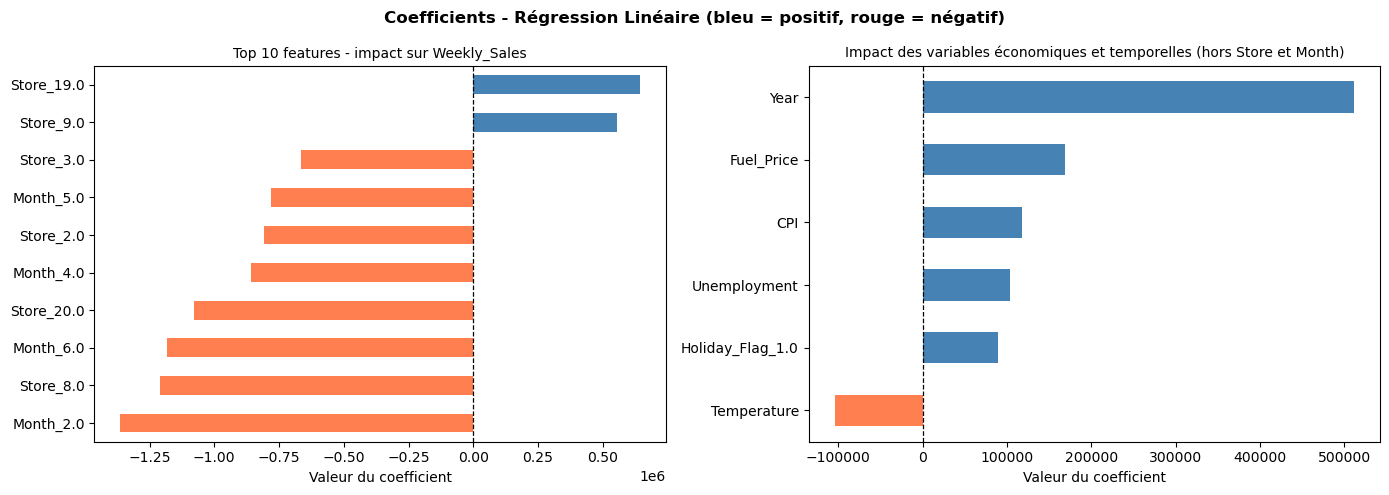

In [ ]:
# Séparation entre les variables Store_x, Month_x et les autres
coefs_autres = coefs[~coefs.index.str.startswith(('Store_', 'Month_'))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Top 10 toutes features ────────────────────────────────────────────
top10      = coefs.abs().sort_values(ascending=False).head(10)
top10_vals = coefs[top10.index].sort_values()
colors_top = ['coral' if v < 0 else 'steelblue' for v in top10_vals]
top10_vals.plot(kind='barh', color=colors_top, ax=axes[0])
axes[0].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[0].set_title("Top 10 features - impact sur Weekly_Sales", fontsize=10)
axes[0].set_xlabel("Valeur du coefficient")

# ── Features economiques et temporelles uniquement ────────────────────
coefs_autres_sorted = coefs_autres.sort_values()
colors_autres = ['coral' if v < 0 else 'steelblue' for v in coefs_autres_sorted]
coefs_autres_sorted.plot(kind='barh', color=colors_autres, ax=axes[1])
axes[1].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[1].set_title("Impact des variables économiques et temporelles (hors Store et Month)", fontsize=10)
axes[1].set_xlabel("Valeur du coefficient")

plt.suptitle("Coefficients - Régression Linéaire (bleu = positif, rouge = négatif)",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

- `Le modèle tente d'apprendre des relations avec la target en utilisant le maximum de features. C'est en combinant tous ces features qu'il arrive à capter et quantifier les variations de la target.` Les features Store et Date (Month, Year) sont les plus importantes pour la prédiction.
- **Store**: l'identité des magasins explique une grande part de la variance des ventes. 
Les coefficients par magasin ne captent pas seulement leur niveau de performance, mais aussi le contexte économique de la région (CPI, chômage, ...).
- **Year/Month** : la date explique aussi une grande part de la variance des ventes. Ça démontre la tendance saisonnière des ventes.
- **Unemployment/CPI** : coefficients positifs significatifs. Le fait qu'ils soient positifs laisse entrevoir une possiblité que l'information qu'ils apportent soit un peu assimiléé par les features Store.
- **Holiday_Flag** : coefficient positif - les semaines de fêtes apportent +7,5% de ventes en moyenne. Possibilié qu'il soit en partie assimilé par les features Month.
- **Fuel_Price**: coefficient positif significatif
- **Temperature**: coefficient négatif significatif.


---
# Partie 3 - Régression régularisée

La régularisation contrôle la complexité du modèle en pénalisant les grands coefficients.

| Méthode | Pénalisation | Effet |
|---------|-------------|-------|
| **Ridge** (L2) | Somme des carrés des coefficients | Réduit les coefficients sans les annuler |
| **Lasso** (L1) | Somme des valeurs absolues | Peut annuler certains coefficients (sélection de variables) |

L'hyperparamètre `alpha` règle la force de la régularisation. Il sera optimisé par GridSearchCV.


## 3.1 Ridge Régression + GridSearchCV

In [46]:
ridge_pipe = Pipeline([
    ('prep',  preprocessor),
    ('model', Ridge())
])

param_grid_ridge = {'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

gs_ridge = GridSearchCV(ridge_pipe, param_grid_ridge, cv=5, scoring='r2', n_jobs=-1)
gs_ridge.fit(X_train, y_train)

best_alpha_r = gs_ridge.best_params_['model__alpha']

r2_ridge_train = r2_score(y_train, gs_ridge.predict(X_train))
r2_ridge_test  = r2_score(y_test,  gs_ridge.predict(X_test))
mae_ridge      = mean_absolute_error(y_test, gs_ridge.predict(X_test))
rmse_ridge     = np.sqrt(mean_squared_error(y_test, gs_ridge.predict(X_test)))

print(f"Meilleur alpha Ridge (GridSearchCV, cv=5) : {best_alpha_r}")
print("=" * 45)
print(f"  R2   Train : {r2_ridge_train:.4f}")
print(f"  R2   Test  : {r2_ridge_test:.4f}")
print(f"  MAE  Test  : {mae_ridge:>12,.0f} $")
print(f"  RMSE Test  : {rmse_ridge:>12,.0f} $")
print(f"  Ecart Train - Test : {r2_ridge_train - r2_ridge_test:.4f}")

Meilleur alpha Ridge (GridSearchCV, cv=5) : 0.01
  R2   Train : 0.9841
  R2   Test  : 0.9757
  MAE  Test  :       83,709 $
  RMSE Test  :      103,738 $
  Ecart Train - Test : 0.0084


### Graphique 9 - R² selon alpha (Ridge - GridSearchCV)

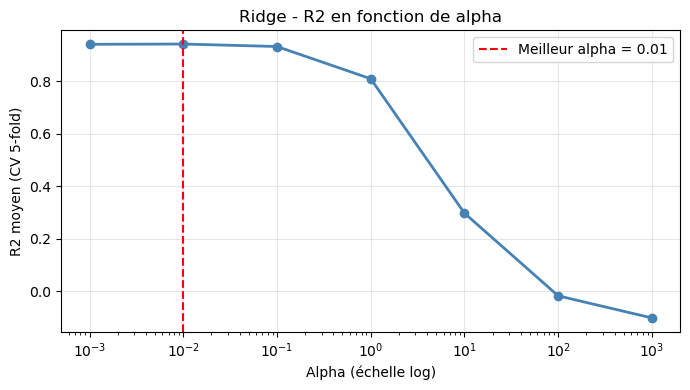

In [47]:
ridge_cv_results = pd.DataFrame(gs_ridge.cv_results_)
alphas_r      = param_grid_ridge['model__alpha']
mean_scores_r = ridge_cv_results['mean_test_score']

plt.figure(figsize=(7, 4))
plt.semilogx(alphas_r, mean_scores_r, marker='o', color='steelblue', linewidth=2)
plt.axvline(best_alpha_r, color='red', linestyle='--', label=f'Meilleur alpha = {best_alpha_r}')
plt.xlabel('Alpha (échelle log)')
plt.ylabel('R2 moyen (CV 5-fold)')
plt.title('Ridge - R2 en fonction de alpha')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Le meilleur alpha est **0,01** : c'est le point où le R² moyen en validation croisée est le plus élevé.
- Au-delà de alpha = 0,01, le R² chute: la régularisation devient trop forte (sous-apprentissage).
- En dessous, le comportement se rapproche d'une régression linéaire classique.
- Ridge nécessite donc une régularisation légère pour généraliser correctement sur ce dataset.


### Graphique 10 - Diagnostic Ridge : Predicted vs Actual et résidus


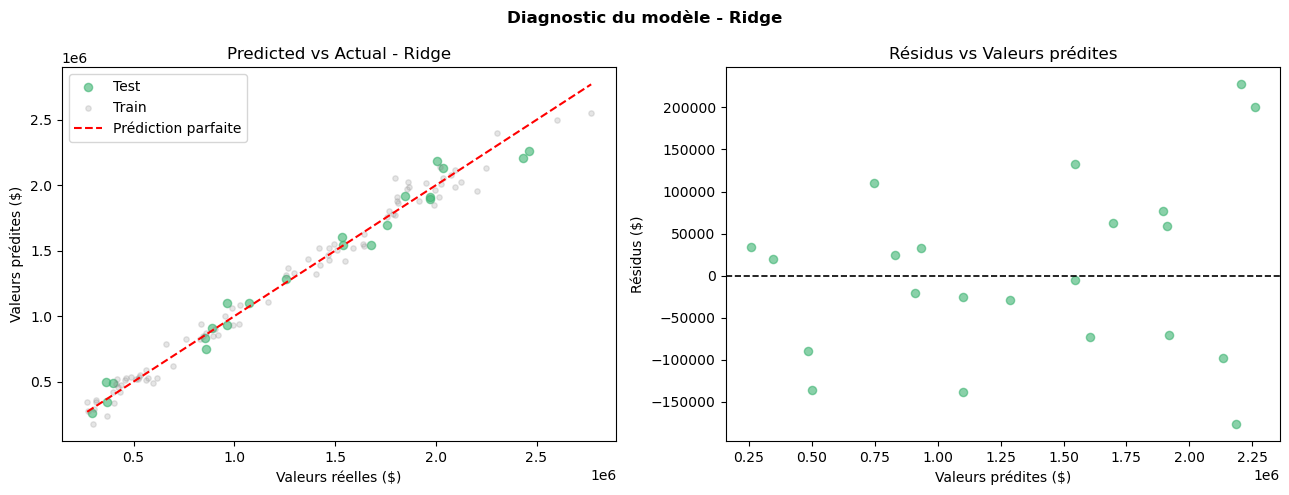

In [48]:
y_pred_ridge_train = gs_ridge.predict(X_train)
y_pred_ridge_test  = gs_ridge.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Predicted vs Actual ───────────────────────────────────────────────
axes[0].scatter(y_test,  y_pred_ridge_test,  alpha=0.6, color='mediumseagreen', s=35, label='Test')
axes[0].scatter(y_train, y_pred_ridge_train, alpha=0.2, color='gray',           s=15, label='Train')
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Prédiction parfaite')
axes[0].set_title('Predicted vs Actual - Ridge')
axes[0].set_xlabel('Valeurs réelles ($)')
axes[0].set_ylabel('Valeurs prédites ($)')
axes[0].legend()

# ── Residus ───────────────────────────────────────────────────────────
residuals_ridge = y_test - y_pred_ridge_test
axes[1].scatter(y_pred_ridge_test, residuals_ridge, alpha=0.6, color='mediumseagreen', s=35)
axes[1].axhline(0, color='black', linewidth=1.2, linestyle='--')
axes[1].set_title('Résidus vs Valeurs prédites')
axes[1].set_xlabel('Valeurs prédites ($)')
axes[1].set_ylabel('Résidus ($)')

plt.suptitle('Diagnostic du modèle - Ridge', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

- La courbe Predicted vs Actual montre un alignement similaire à la régression linéaire.
- Les résidus restent centrés sur 0 et leur dispersion est simalaire à ce qui a été obtenue précédemment. 
- Comme on n'avait pas d'Overfitting avec le premier modèle, l'amélioration de Ridge sur ce dataset est légère (R² inchangé, MAE et RMSE diminuent respectivement de 4000$ et 3000$).


Features importance (|coef|) :
Month_2.0           1.338545e+06
Store_8.0           1.191065e+06
Month_6.0           1.154254e+06
Store_20.0          1.051520e+06
Month_4.0           8.447827e+05
Store_2.0           7.919350e+05
Month_5.0           7.567106e+05
Store_19.0          6.521324e+05
Store_3.0           6.395886e+05
Store_9.0           5.709718e+05
Year                5.066254e+05
Store_18.0          4.923185e+05
Store_15.0          4.703571e+05
Store_6.0           3.308770e+05
Store_7.0           2.924369e+05
Month_7.0           2.588491e+05
Store_16.0          2.335469e+05
Month_11.0          1.737654e+05
Store_4.0           1.632670e+05
Fuel_Price          1.543200e+05
Store_11.0          1.430468e+05
Store_17.0          1.358023e+05
Month_8.0           1.328501e+05
Month_10.0          1.123039e+05
CPI                 1.017232e+05
Temperature         1.011546e+05
Month_12.0          9.959497e+04
Month_9.0           9.929422e+04
Unemployment        9.233116e+04
Holiday_Flag

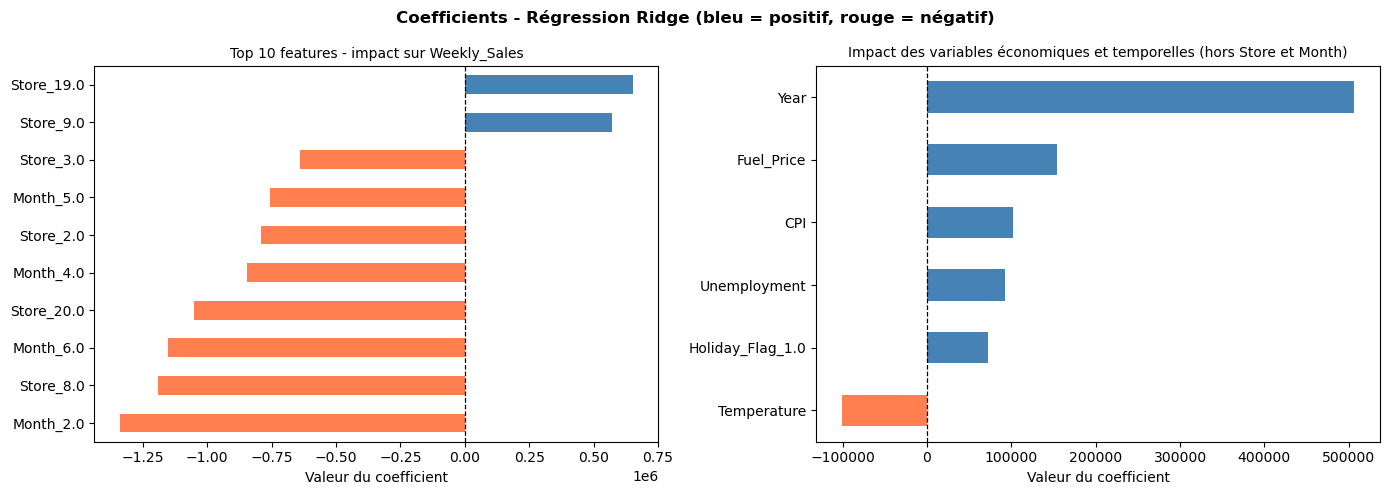

In [52]:
# Extraction et affichage des coefficients du modele
ohe_feature_names = (ridge_pipe.named_steps['prep']
                             .named_transformers_['cat']
                             .get_feature_names_out(cat_cols).tolist())

feature_names = ohe_feature_names + num_cols
coefs = pd.Series(gs_ridge.best_estimator_.named_steps['model'].coef_, index=feature_names)

print("Features importance (|coef|) :")
print(coefs.abs().sort_values(ascending=False))

# Séparation entre les variables Store_x et les autres
coefs_autres = coefs[~coefs.index.str.startswith(('Store_', 'Month_'))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Top 10 toutes features ────────────────────────────────────────────
top10      = coefs.abs().sort_values(ascending=False).head(10)
top10_vals = coefs[top10.index].sort_values()
colors_top = ['coral' if v < 0 else 'steelblue' for v in top10_vals]
top10_vals.plot(kind='barh', color=colors_top, ax=axes[0])
axes[0].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[0].set_title("Top 10 features - impact sur Weekly_Sales", fontsize=10)
axes[0].set_xlabel("Valeur du coefficient")

# ── Features economiques et temporelles uniquement ────────────────────
coefs_autres_sorted = coefs_autres.sort_values()
colors_autres = ['coral' if v < 0 else 'steelblue' for v in coefs_autres_sorted]
coefs_autres_sorted.plot(kind='barh', color=colors_autres, ax=axes[1])
axes[1].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[1].set_title("Impact des variables économiques et temporelles (hors Store et Month)", fontsize=10)
axes[1].set_xlabel("Valeur du coefficient")

plt.suptitle("Coefficients - Régression Ridge (bleu = positif, rouge = négatif)",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

L'importance des features n'a pas changée. Ridge a atténué un petit peu les coéfficients sans en annuler un.

## 3.2 Lasso Régression + GridSearchCV

In [53]:
lasso_pipe = Pipeline([
    ('prep',  preprocessor),
    ('model', Lasso(max_iter=500000))
])

param_grid_lasso = {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000, 10000]}

gs_lasso = GridSearchCV(lasso_pipe, param_grid_lasso, cv=5, scoring='r2', n_jobs=-1)
gs_lasso.fit(X_train, y_train)

best_alpha_l = gs_lasso.best_params_['model__alpha']

r2_lasso_train = r2_score(y_train, gs_lasso.predict(X_train))
r2_lasso_test  = r2_score(y_test,  gs_lasso.predict(X_test))
mae_lasso      = mean_absolute_error(y_test, gs_lasso.predict(X_test))
rmse_lasso     = np.sqrt(mean_squared_error(y_test, gs_lasso.predict(X_test)))

lasso_coefs = gs_lasso.best_estimator_.named_steps['model'].coef_
n_zero = np.sum(np.abs(lasso_coefs) < 1e-6)

print(f"Meilleur alpha Lasso (GridSearchCV, cv=5) : {best_alpha_l}")
print("=" * 45)
print(f"  R2   Train : {r2_lasso_train:.4f}")
print(f"  R2   Test  : {r2_lasso_test:.4f}")
print(f"  MAE  Test  : {mae_lasso:>12,.0f} $")
print(f"  RMSE Test  : {rmse_lasso:>12,.0f} $")
print(f"  Écart Train - Test : {r2_lasso_train - r2_lasso_test:.4f}")
print(f"  Coefficients annulés par Lasso : {n_zero} / {len(lasso_coefs)}")

Meilleur alpha Lasso (GridSearchCV, cv=5) : 1000
  R2   Train : 0.9818
  R2   Test  : 0.9768
  MAE  Test  :       76,396 $
  RMSE Test  :      101,263 $
  Écart Train - Test : 0.0050
  Coefficients annulés par Lasso : 8 / 36


### Graphique 11 - R² selon alpha (Lasso - GridSearchCV)

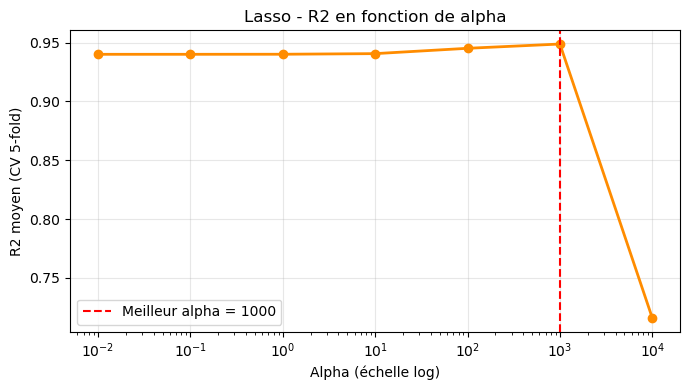

In [55]:
lasso_cv_results = pd.DataFrame(gs_lasso.cv_results_)
mean_scores_l    = lasso_cv_results['mean_test_score']

plt.figure(figsize=(7, 4))
plt.semilogx(param_grid_lasso['model__alpha'], mean_scores_l,
             marker='o', color='darkorange', linewidth=2)
plt.axvline(best_alpha_l, color='red', linestyle='--', label=f'Meilleur alpha = {best_alpha_l}')
plt.xlabel('Alpha (échelle log)')
plt.ylabel('R2 moyen (CV 5-fold)')
plt.title('Lasso - R2 en fonction de alpha')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Graphique 12 - Diagnostic Lasso : Predicted vs Actual et résidus


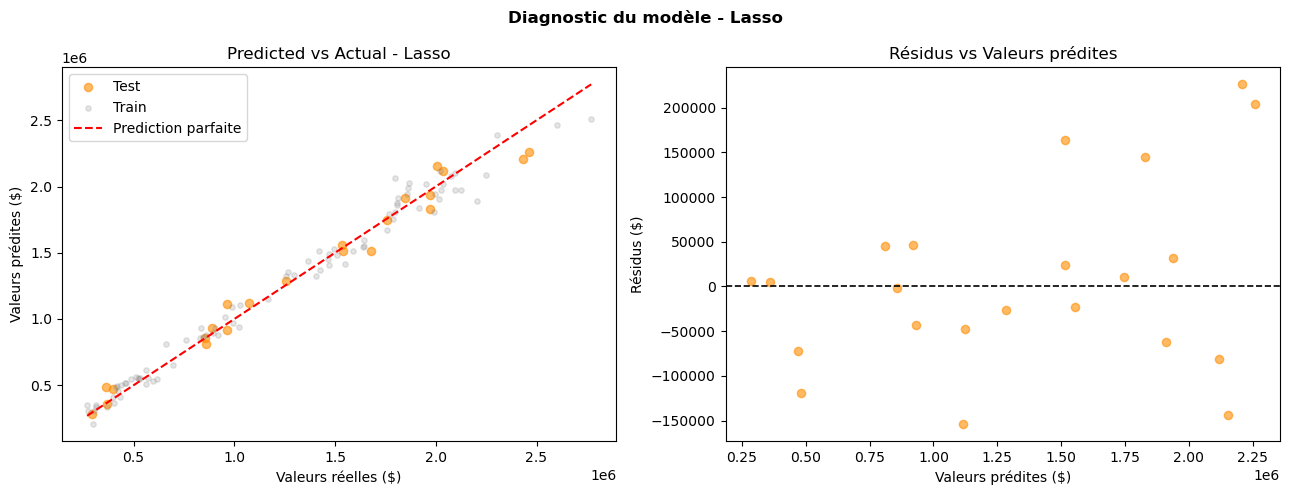

In [56]:
y_pred_lasso_train = gs_lasso.predict(X_train)
y_pred_lasso_test  = gs_lasso.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Predicted vs Actual ───────────────────────────────────────────────
axes[0].scatter(y_test,  y_pred_lasso_test,  alpha=0.6, color='darkorange', s=35, label='Test')
axes[0].scatter(y_train, y_pred_lasso_train, alpha=0.2, color='gray',       s=15, label='Train')
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Prediction parfaite')
axes[0].set_title('Predicted vs Actual - Lasso')
axes[0].set_xlabel('Valeurs réelles ($)')
axes[0].set_ylabel('Valeurs prédites ($)')
axes[0].legend()

# ── Residus ───────────────────────────────────────────────────────────
residuals_lasso = y_test - y_pred_lasso_test
axes[1].scatter(y_pred_lasso_test, residuals_lasso, alpha=0.6, color='darkorange', s=35)
axes[1].axhline(0, color='black', linewidth=1.2, linestyle='--')
axes[1].set_title('Résidus vs Valeurs prédites')
axes[1].set_xlabel('Valeurs prédites ($)')
axes[1].set_ylabel('Résidus ($)')

plt.suptitle('Diagnostic du modèle - Lasso', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

- La courbe Predicted vs Actual montre un alignement similaire à la régression linéaire.
- Les résidus restent centrés sur 0 et leur dispersion est simalaire à ce qui a été obtenue précédemment. 
- Lasso fait baisser encore les erreurs (MAE et RMSE diminuent respectivement de 11000$ et 5000$ par rapport à la regression linéaire).


### Graphique 13 - Coefficients Lasso : variables retenues et annulées

Features importance (|coef|) :
Month_2.0           1.296488e+06
Store_8.0           1.159137e+06
Month_6.0           1.065614e+06
Store_20.0          1.004461e+06
Month_4.0           8.338355e+05
Store_2.0           8.083441e+05
Month_5.0           7.135848e+05
Store_3.0           6.386831e+05
Store_19.0          6.184866e+05
Store_9.0           5.162306e+05
Store_18.0          4.449784e+05
Year                4.321590e+05
Store_15.0          3.924279e+05
Store_6.0           3.238917e+05
Store_7.0           2.583698e+05
Store_4.0           1.945451e+05
Month_7.0           1.739154e+05
Store_16.0          1.351789e+05
Store_11.0          1.258194e+05
Month_11.0          5.713193e+04
Fuel_Price          5.221502e+04
Temperature         5.130634e+04
Store_14.0          3.674613e+04
Month_8.0           3.027981e+04
Store_10.0          2.598810e+04
Store_12.0          2.074225e+04
Month_10.0          8.393014e+03
Store_13.0          5.926043e+03
Month_3.0           0.000000e+00
Store_5.0   

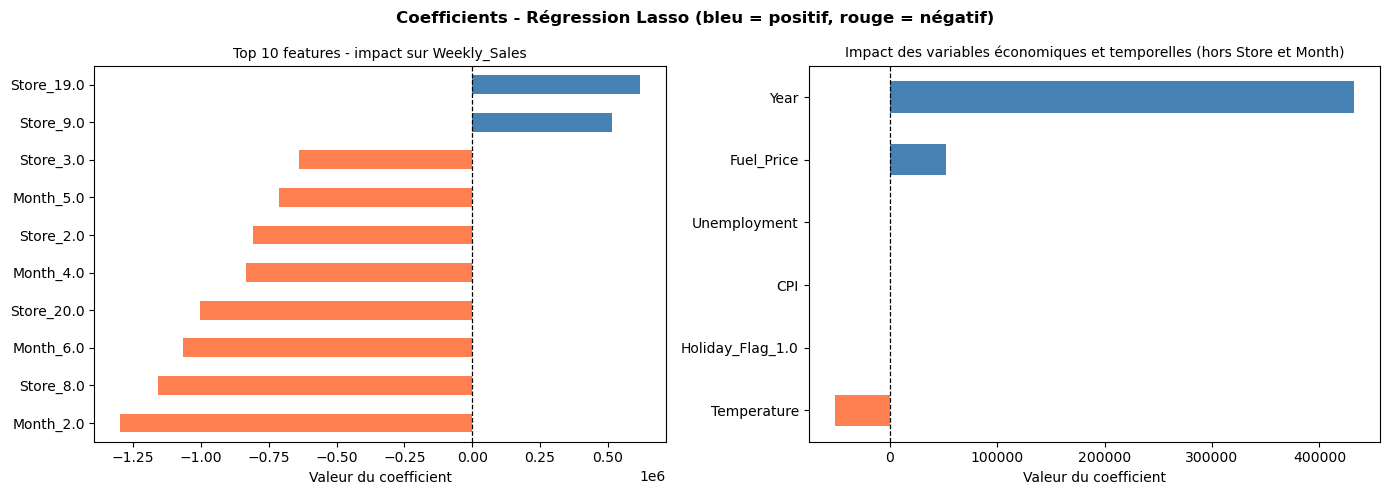

Coefficients annulés (= 0) :
['Store_17.0', 'Store_5.0', 'Month_3.0', 'Month_9.0', 'Month_12.0', 'Holiday_Flag_1.0', 'CPI', 'Unemployment']


In [61]:
ohe_feature_names = (lasso_pipe.named_steps['prep']
                             .named_transformers_['cat']
                             .get_feature_names_out(cat_cols).tolist())

feature_names = ohe_feature_names + num_cols
coefs = pd.Series(gs_lasso.best_estimator_.named_steps['model'].coef_, index=feature_names)

print("Features importance (|coef|) :")
print(coefs.abs().sort_values(ascending=False))

# Séparation entre les variables Store_x, Month_x et les autres
coefs_autres = coefs[~coefs.index.str.startswith(('Store_', 'Month_'))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Top 10 toutes features ────────────────────────────────────────────
top10      = coefs.abs().sort_values(ascending=False).head(10)
top10_vals = coefs[top10.index].sort_values()
colors_top = ['coral' if v < 0 else 'steelblue' for v in top10_vals]
top10_vals.plot(kind='barh', color=colors_top, ax=axes[0])
axes[0].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[0].set_title("Top 10 features - impact sur Weekly_Sales", fontsize=10)
axes[0].set_xlabel("Valeur du coefficient")

# ── Features economiques et temporelles uniquement ────────────────────
coefs_autres_sorted = coefs_autres.sort_values()
colors_autres = ['coral' if v < 0 else 'steelblue' for v in coefs_autres_sorted]
coefs_autres_sorted.plot(kind='barh', color=colors_autres, ax=axes[1])
axes[1].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[1].set_title("Impact des variables économiques et temporelles (hors Store et Month)", fontsize=10)
axes[1].set_xlabel("Valeur du coefficient")

plt.suptitle("Coefficients - Régression Lasso (bleu = positif, rouge = négatif)",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Coefficients annulés (= 0) :")
print(coefs[np.abs(coefs) < 1e-6].index.tolist())

- L'importance des features n'a pas changée. Lasso a atténué les coéfficients (encore plus que Ridge) en annulant les coefficients des features peu informatives - c'est sa propriété de sélection de variables.
- Parmi les features annulées (8 au total): les indicateurs économiques CPI et Unemployment --> les informations qu'elles apportent sont contenues dans Store,  Holiday_Flag --> assimilé dans Month.
- **Lasso réduit encore plus les coefficients en supprimant les features qui apportent peu d'information prédictive supplémentaire --> ça rend le modèle plus simple.**


## 3.3 Comparaison des trois modèles

In [64]:
models_label = ['Lin. Regression', f'Ridge (a={best_alpha_r})', f'Lasso (a={best_alpha_l})']
r2_trains = [r2_train,  r2_ridge_train, r2_lasso_train]
r2_tests  = [r2_test,   r2_ridge_test,  r2_lasso_test]
mae_vals  = [mae_test,  mae_ridge,      mae_lasso]
rmse_vals = [rmse_test, rmse_ridge,     rmse_lasso]

summary = pd.DataFrame({
    'Modele'       : models_label,
    'R2 Train'     : [f"{v:.4f}" for v in r2_trains],
    'R2 Test'      : [f"{v:.4f}" for v in r2_tests],
    'MAE Test ($)' : [f"{v:,.0f}" for v in mae_vals],
    'RMSE Test ($)': [f"{v:,.0f}" for v in rmse_vals],
    'Ecart Train-Test': [f"{tr-te:.4f}" for tr, te in zip(r2_trains, r2_tests)]
})
print(summary.to_string(index=False))

         Modele R2 Train R2 Test MAE Test ($) RMSE Test ($) Ecart Train-Test
Lin. Regression   0.9841  0.9742       87,636       106,779           0.0099
 Ridge (a=0.01)   0.9841  0.9757       83,709       103,738           0.0084
 Lasso (a=1000)   0.9818  0.9768       76,396       101,263           0.0050


### Graphique 14 - Comparaison des modèles (R², MAE, RMSE)

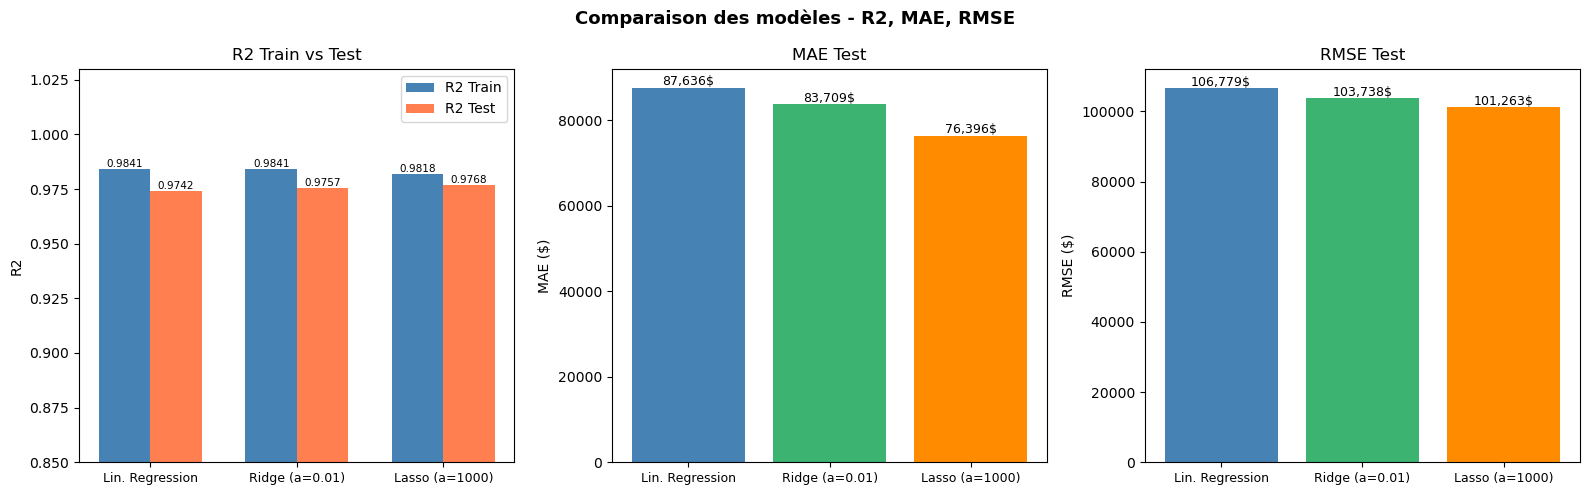

In [65]:
x     = np.arange(len(models_label))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── R² Train vs Test ──────────────────────────────────────────────────
bars1 = axes[0].bar(x - width/2, r2_trains, width, label='R2 Train', color='steelblue')
bars2 = axes[0].bar(x + width/2, r2_tests,  width, label='R2 Test',  color='coral')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_label, fontsize=9)
axes[0].set_ylabel('R2')
axes[0].set_ylim(0.85, 1.03)
axes[0].set_title('R2 Train vs Test')
axes[0].legend()
for b in list(bars1) + list(bars2):
    axes[0].annotate(f'{b.get_height():.4f}',
                     xy=(b.get_x() + b.get_width() / 2, b.get_height()),
                     ha='center', va='bottom', fontsize=7.5)

# ── MAE Test ──────────────────────────────────────────────────────────
axes[1].bar(x, mae_vals, color=['steelblue', 'mediumseagreen', 'darkorange'])
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_label, fontsize=9)
axes[1].set_title('MAE Test')
axes[1].set_ylabel('MAE ($)')
for i, v in enumerate(mae_vals):
    axes[1].text(i, v + 500, f'{v:,.0f}$', ha='center', fontsize=9)

# ── RMSE Test ─────────────────────────────────────────────────────────
axes[2].bar(x, rmse_vals, color=['steelblue', 'mediumseagreen', 'darkorange'])
axes[2].set_xticks(x)
axes[2].set_xticklabels(models_label, fontsize=9)
axes[2].set_title('RMSE Test')
axes[2].set_ylabel('RMSE ($)')
for i, v in enumerate(rmse_vals):
    axes[2].text(i, v + 500, f'{v:,.0f}$', ha='center', fontsize=9)

plt.suptitle('Comparaison des modèles - R2, MAE, RMSE', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**R²**
- Les trois modèles apprennent bien les données d'entraînement (R² Train 0,98) sans overfitting (R² Test 0,97).

**MAE/RMSE**
- La régression linéaire commet une erreur moyenne (MAE) de ~88 000$ par prédiction.
- Ridge réduit l'erreur MAE d'environ 4.6%, Lasso d'environ 12.6%.
- Ridge réduit l'erreur RMSE d'environ 3%, Lasso d'environ 4.7%.



---
## Conclusion

### Résumé des performances

| Modele | R2 Train | R2 Test | MAE Test ($) | RMSE Test ($) | Ecart R2 Train-Test |
|--------|----------|---------|----------|-----------|-----------------|
|Lin. Regression |  0.9841 | 0.9742  |     87,636  |     106,779  |         0.0099
| Ridge (a=0.01) |  0.9841 | 0.9757  |     83,709  |     103,738  |         0.0084
| Lasso (a=1000) |  0.9818 | 0.9768  |     76,396  |     101,263  |         0.0050

Le modèle **Lasso est recommandé** : erreurs plus petites et modèle plus parcimonieux. Lasso ne garde que les features essentielles pour la prédiction.

### Variables explicatives les plus importantes

- **Store** - forte hétérogénéité inter-magasins - performance structurelle (taille, localisation, clientèle) + contexte économique.
- **Year/Month** - Tendance saisonnière.

---
### Recommendations pour le service marketing
- Concentrer les budgets promotionnels sur les périodes de fêtes ; planifier les campagnes à l'avance.
- Renforcer les offres de fidélisation et les promotions défensives sur les produits essentiels lors des phases d'inflation.
- Adapter la stratégie promotionnelle par zone géographique ; intensifier les offres dans les bassins d'emploi fragilisés.

### Limites et perspectives

**Limites :**

- Dataset réduit - résultats à confirmer sur un dataset plus large.
- La régression linéaire suppose une relation linéaire entre X et y.

**Perspectives :**

- Tester des modèles non linéaires : Random Forest, XGBoost.
- Enrichir le dataset avec des données externes (météo, événements locaux, indices de confiance des consommateurs).
- Mettre en production via une API pour prédiction en temps réel et intégration dans les outils du service marketing.
